# **02 Exploratory Analysis**
This notebook explores the GDP SST and drifter movement analysis during the 2013-2016 Blob and 2019-2020 marine heatwave. **This notebook consists of the exploratory data analysis (EDA) part of our initial Project Proposal, NOT our final report**

**Input:** ../data/processed/california_current_new.zarr (Notebook 01)

**Study Region:** 25-48°N, 135-115°W

**Study Period:** 2013-2016 "The Blob" and 2012-2021 "Major Heatwave" Events

### Objectives

Aims of the EDA:
- assess the spatial and temporal coverage of GDP observations
- evaluate the availability and quality of SST measurements
- explore seasonal and interannual SST variability
- assess data coverage during the target marine heatwave period (2019-2021)
- evaluate the availability and distribution of drifter velocity measurements
- identify sampling limitations relvant to subsequent marine heatwave analysis

In [ ]:
# import necessary libraries
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the processed California Current dataset
Open the regional GDP subset produced by Notebook 01

In [2]:
# opening regional subset dataset (California Current)
cc = xr.open_zarr(
    "../data/processed/california_current_new.zarr"
)

cc

<xarray.Dataset> Size: 69MB
Dimensions:  (obs: 1412827, traj: 341)
Coordinates:
    id       (traj) int64 3kB ...
    time     (obs) datetime64[ns] 11MB ...
Dimensions without coordinates: obs, traj
Data variables:
    err_sst  (obs) float32 6MB ...
    flg_sst  (obs) int8 1MB ...
    lat      (obs) float64 11MB ...
    lon      (obs) float64 11MB ...
    rowsize  (traj) int32 1kB ...
    sst      (obs) float32 6MB ...
    sst1     (obs) float32 6MB ...
    sst2     (obs) float32 6MB ...
    ve       (obs) float32 6MB ...
    vn       (obs) float32 6MB ...
Attributes: (12/18)
    Conventions:          CF-1.6
    acknowledgement:      Elipot, Shane; Sykulski, Adam; Lumpkin, Rick; Centu...
    contributor_name:     NOAA Global Drifter Program
    contributor_role:     Data Acquisition Center
    date_created:         2024-07-30T19:02:16.200531
    doi:                  10.25921/x46c-3620
    ...                   ...
    publisher_name:       GDP Drifter DAC
    publisher_url:        https://www.aoml.noaa.gov/phod/gdp
    summary:              Global Drifter Program hourly data
    time_coverage_end:    2022-10-31:00:00:00Z
    time_coverage_start:  1987-10-02:13:00:00Z
    title:                Global Drifter Program hourly drifting buoy collection

In [3]:
inside = (
    (cc["lat"] >= 25) &
    (cc["lat"] <= 48) &
    (cc["lon"] >= -135) &
    (cc["lon"] <= -115)
)

print("Observations inside box:", int(inside.sum()))

Observations inside box: 1412827


## 2. Prepare SST quality masks and event periods
Identify observations with SST quality flag 5 and define the two historical event windows

In [4]:
# Data quality masks
valid_velocity = (
    cc["ve"].notnull() &
    cc["vn"].notnull()
)

good_sst = inside & (cc["flg_sst"] == 5)

# SST in celsius
sst_c = cc["sst"].where(good_sst) - 273.15

# Historical event periods
blob = (
    inside &
    (cc["time"].dt.year >= 2013) &
    (cc["time"].dt.year <= 2016)
)

mhw_2019 = (
    inside &
    (cc["time"].dt.year >= 2019) &
    (cc["time"].dt.year <= 2020)
)

# High-quality SST during each event
blob_good = blob & (cc["flg_sst"] == 5)
mhw_2019_good = mhw_2019 & (cc["flg_sst"] == 5)

## 3. Construct an exploratory GDP-based SST anomaly
Convert SST from kelvin to Celsius, calculate a monthly median for each 0.5° latitude-longitude grid cell using the 2012-2021 GDP sample, and subtract it from each observation. 

In [6]:
good_sst = inside & (cc["flg_sst"] == 5)

sst_df = pd.DataFrame({
    "time": cc["time"].where(good_sst, drop=True).values,
    "lat": cc["lat"].where(good_sst, drop=True).values,
    "lon": cc["lon"].where(good_sst, drop=True).values,
    "sst": cc["sst"].where(good_sst, drop=True).values
})

sst_df["sst_c"] = sst_df["sst"] - 273.15

sst_df.head()

len(sst_df)

1358083

In [7]:
sst_df["year"] = sst_df["time"].dt.year
sst_df["month"] = sst_df["time"].dt.month

sst_df[["time", "year", "month", "sst_c"]].head()

,time,year,month,sst_c
0,2013-06-08 09:00:00,2013,6,11.694000
1,2013-06-08 10:00:00,2013,6,11.675018
2,2013-06-08 11:00:00,2013,6,11.643005
3,2013-06-08 12:00:00,2013,6,11.610992
4,2013-06-08 13:00:00,2013,6,11.593018


In [8]:
grid_size = 0.5

sst_df["lat_bin"] = (
    np.floor(sst_df["lat"] / grid_size) * grid_size
)

sst_df["lon_bin"] = (
    np.floor(sst_df["lon"] / grid_size) * grid_size
)

sst_df[
    ["lat", "lon", "lat_bin", "lon_bin"]
].head()

,lat,lon,lat_bin,lon_bin
0,46.073181,-134.991623,46.0,-135.0
1,46.077641,-134.981186,46.0,-135.0
2,46.069801,-134.971878,46.0,-135.0
3,46.065510,-134.960922,46.0,-135.0
4,46.059978,-134.951523,46.0,-135.0


In [9]:
climatology = (
    sst_df
    .groupby(["lat_bin", "lon_bin", "month"])["sst_c"]
    .median()
    .reset_index(name="baseline_sst")
)

climatology.head()

,lat_bin,lon_bin,month,baseline_sst
0,25.0,-135.0,1,19.760010
1,25.0,-135.0,2,20.278778
2,25.0,-135.0,3,20.005341
3,25.0,-135.0,5,20.256958
4,25.0,-135.0,7,21.895508


In [10]:
sst_df = sst_df.merge(
    climatology,
    on=["lat_bin", "lon_bin", "month"],
    how="left"
)

sst_df[
    ["time", "lat", "lon", "sst_c", "baseline_sst"]
].head()

,time,lat,lon,sst_c,baseline_sst
0,2013-06-08 09:00:00,46.073181,-134.991623,11.694000,11.688995
1,2013-06-08 10:00:00,46.077641,-134.981186,11.675018,11.688995
2,2013-06-08 11:00:00,46.069801,-134.971878,11.643005,11.688995
3,2013-06-08 12:00:00,46.065510,-134.960922,11.610992,11.688995
4,2013-06-08 13:00:00,46.059978,-134.951523,11.593018,11.688995


In [11]:
sst_df["sst_anomaly"] = (
    sst_df["sst_c"] -
    sst_df["baseline_sst"]
)

sst_df[
    [
        "time",
        "lat",
        "lon",
        "sst_c",
        "baseline_sst",
        "sst_anomaly"
    ]
].head(10)

,time,lat,lon,sst_c,baseline_sst,sst_anomaly
0,2013-06-08 09:00:00,46.073181,-134.991623,11.694000,11.688995,0.005005
1,2013-06-08 10:00:00,46.077641,-134.981186,11.675018,11.688995,-0.013977
2,2013-06-08 11:00:00,46.069801,-134.971878,11.643005,11.688995,-0.045990
3,2013-06-08 12:00:00,46.065510,-134.960922,11.610992,11.688995,-0.078003
4,2013-06-08 13:00:00,46.059978,-134.951523,11.593018,11.688995,-0.095978
5,2013-06-08 14:00:00,46.055431,-134.951462,11.601013,11.688995,-0.087982
6,2013-06-08 15:00:00,46.051720,-134.952057,11.630005,11.688995,-0.058990
7,2013-06-08 16:00:00,46.049492,-134.957153,11.670013,11.688995,-0.018982
8,2013-06-08 17:00:00,46.049450,-134.963333,11.704010,11.688995,0.015015
9,2013-06-08 18:00:00,46.049210,-134.968735,11.722015,11.688995,0.033020


In [12]:
sst_df["sst_anomaly"].describe()

count    1.358083e+06
mean     1.499253e-02
std      6.638128e-01
min     -1.572101e+01
25%     -1.475067e-01
50%      0.000000e+00
75%      1.678772e-01
max      2.255151e+01
Name: sst_anomaly, dtype: float64

In [13]:
print(
    "1st percentile:",
    sst_df["sst_anomaly"].quantile(0.01)
)

print(
    "99th percentile:",
    sst_df["sst_anomaly"].quantile(0.99)
)

1st percentile: -2.1799676513671873
99th percentile: 2.24285888671875


In [14]:
print(
    "Missing anomalies:",
    sst_df["sst_anomaly"].isna().sum()
)

Missing anomalies: 0


## 4. Compare exploratory spatial SST anomalies
Aggregate SST anomalies by grid cell within each event. 

In [15]:
blob_df = sst_df[
    (sst_df["year"] >= 2013) &
    (sst_df["year"] <= 2016)
].copy()

mhw_df = sst_df[
    (sst_df["year"] >= 2019) &
    (sst_df["year"] <= 2020)
].copy()

In [ ]:
print("Blob observations:", len(blob_df))
print("2019–2020 observations:", len(mhw_df))

Blob observations: 543427
2019–2021 observations: 300514


In [17]:
blob_anomaly_grid = (
    blob_df
    .groupby(["lat_bin", "lon_bin"])
    .agg(
        median_anomaly=("sst_anomaly", "median"),
        n_obs=("sst_anomaly", "size")
    )
    .reset_index()
)

mhw_anomaly_grid = (
    mhw_df
    .groupby(["lat_bin", "lon_bin"])
    .agg(
        median_anomaly=("sst_anomaly", "median"),
        n_obs=("sst_anomaly", "size")
    )
    .reset_index()
)

In [18]:
min_obs = 20

blob_anomaly_plot = blob_anomaly_grid[
    blob_anomaly_grid["n_obs"] >= min_obs
].copy()

mhw_anomaly_plot = mhw_anomaly_grid[
    mhw_anomaly_grid["n_obs"] >= min_obs
].copy()

In [20]:
all_anomalies = pd.concat([
    blob_anomaly_plot["median_anomaly"],
    mhw_anomaly_plot["median_anomaly"]
])

limit = max(
    abs(all_anomalies.quantile(0.02)),
    abs(all_anomalies.quantile(0.98))
)

print("Colour limit:", limit)

Colour limit: 1.1015954589843764


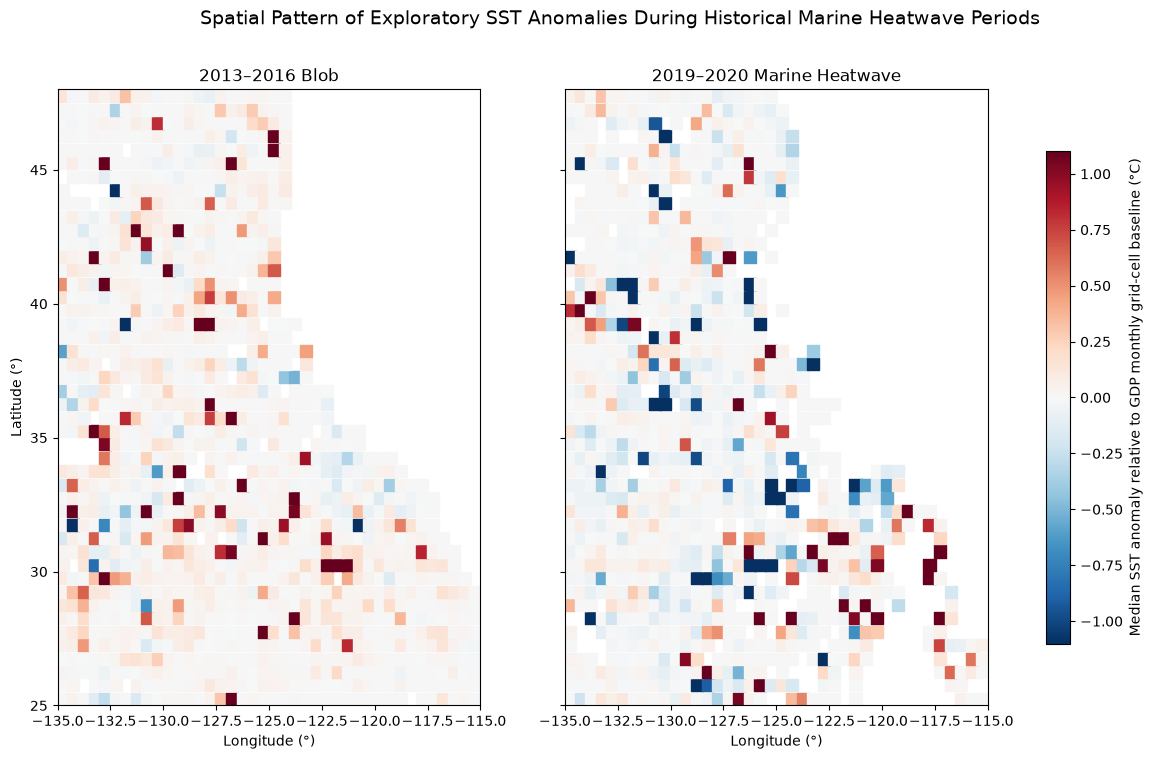

In [21]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    sharex=True,
    sharey=True
)

# 2013–2016 Blob
sc1 = axes[0].scatter(
    blob_anomaly_plot["lon_bin"] + 0.25,
    blob_anomaly_plot["lat_bin"] + 0.25,
    c=blob_anomaly_plot["median_anomaly"],
    s=75,
    marker="s",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

axes[0].set_title("2013–2016 Blob")
axes[0].set_xlabel("Longitude (°)")
axes[0].set_ylabel("Latitude (°)")
axes[0].set_xlim(-135, -115)
axes[0].set_ylim(25, 48)


# 2019–2021 MHW
sc2 = axes[1].scatter(
    mhw_anomaly_plot["lon_bin"] + 0.25,
    mhw_anomaly_plot["lat_bin"] + 0.25,
    c=mhw_anomaly_plot["median_anomaly"],
    s=75,
    marker="s",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit
)

axes[1].set_title("2019–2020 Marine Heatwave")
axes[1].set_xlabel("Longitude (°)")
axes[1].set_xlim(-135, -115)
axes[1].set_ylim(25, 48)


# Shared colourbar
cbar = fig.colorbar(
    sc2,
    ax=axes,
    shrink=0.8
)

cbar.set_label(
    "Median SST anomaly relative to GDP monthly grid-cell baseline (°C)"
)

fig.suptitle(
    "Spatial Pattern of Exploratory SST Anomalies During Historical Marine Heatwave Periods",
    fontsize=14
)

plt.show()

*This is Figure 1 in our Project Proposal, not in our final report*

In [22]:
comparison = pd.DataFrame({
    "Metric": [
        "Median grid-cell anomaly (°C)",
        "Mean grid-cell anomaly (°C)",
        "Grid cells warmer than baseline (%)",
        "Grid cells > +0.5°C (%)",
        "Grid cells > +1.0°C (%)",
        "90th percentile anomaly (°C)"
    ],

    "2013–2016 Blob": [
        blob_anomaly_plot["median_anomaly"].median(),
        blob_anomaly_plot["median_anomaly"].mean(),
        (blob_anomaly_plot["median_anomaly"] > 0).mean() * 100,
        (blob_anomaly_plot["median_anomaly"] > 0.5).mean() * 100,
        (blob_anomaly_plot["median_anomaly"] > 1.0).mean() * 100,
        blob_anomaly_plot["median_anomaly"].quantile(0.90)
    ],

    "2019–2020 MHW": [
        mhw_anomaly_plot["median_anomaly"].median(),
        mhw_anomaly_plot["median_anomaly"].mean(),
        (mhw_anomaly_plot["median_anomaly"] > 0).mean() * 100,
        (mhw_anomaly_plot["median_anomaly"] > 0.5).mean() * 100,
        (mhw_anomaly_plot["median_anomaly"] > 1.0).mean() * 100,
        mhw_anomaly_plot["median_anomaly"].quantile(0.90)
    ]
})

comparison.round(2)

,Metric,2013–2016 Blob,2019–2020 MHW
0,Median grid-cell anomaly (°C),0.01,0.00
1,Mean grid-cell anomaly (°C),0.07,-0.02
2,Grid cells warmer than baseline (%),61.86,38.34
3,Grid cells > +0.5°C (%),4.47,4.61
4,Grid cells > +1.0°C (%),2.39,2.58
5,90th percentile anomaly (°C),0.16,0.13


## 5. Approximate coastal versus offshore thermal exposure
Classify longitude >= -125° as a coastal sector and longitude < -125° as offshore. This is for exploratory analysis only, and not equivalent to the 50 km coastline-distance threshold in subsequent analysis.

In [24]:
blob_zone = blob_anomaly_plot.copy()
mhw_zone = mhw_anomaly_plot.copy()

In [25]:
blob_zone["zone"] = np.where(
    blob_zone["lon_bin"] >= -125,
    "Coastal",
    "Offshore"
)

mhw_zone["zone"] = np.where(
    mhw_zone["lon_bin"] >= -125,
    "Coastal",
    "Offshore"
)

In [27]:
def zone_summary(df):

    return (
        df.groupby("zone")
        .agg(
            grid_cells=("median_anomaly", "size"),

            median_anomaly=(
                "median_anomaly",
                "median"
            ),

            mean_anomaly=(
                "median_anomaly",
                "mean"
            ),

            positive_pct=(
                "median_anomaly",
                lambda x: (x > 0).mean() * 100
            ),

            above_05_pct=(
                "median_anomaly",
                lambda x: (x > 0.5).mean() * 100
            ),

            above_10_pct=(
                "median_anomaly",
                lambda x: (x > 1.0).mean() * 100
            )
        )
        .round(2)
    )

In [28]:
blob_zone_summary = zone_summary(blob_zone)
mhw_zone_summary = zone_summary(mhw_zone)

print("2013–2016 Blob")
display(blob_zone_summary)

print("2019–2020 MHW")
display(mhw_zone_summary)

2013–2016 Blob


,grid_cells,median_anomaly,mean_anomaly,positive_pct,above_05_pct,above_10_pct
zone,,,,,,
Coastal,413,0.01,0.06,57.869999,3.63,1.94
Offshore,885,0.01,0.08,63.730000,4.86,2.60


2019–2020 MHW


,grid_cells,median_anomaly,mean_anomaly,positive_pct,above_05_pct,above_10_pct
zone,,,,,,
Coastal,232,0.0,0.08,39.66,10.34,6.47
Offshore,853,0.0,-0.04,37.98,3.05,1.52


In [29]:
blob_zone_summary["event"] = "2013–2016 Blob"
mhw_zone_summary["event"] = "2019–2020 MHW"

zone_comparison = pd.concat([
    blob_zone_summary.reset_index(),
    mhw_zone_summary.reset_index()
])

zone_comparison

,zone,grid_cells,median_anomaly,mean_anomaly,positive_pct,above_05_pct,above_10_pct,event
0,Coastal,413,0.01,0.06,57.869999,3.63,1.94,2013–2016 Blob
1,Offshore,885,0.01,0.08,63.730000,4.86,2.60,2013–2016 Blob
0,Coastal,232,0.00,0.08,39.660000,10.34,6.47,2019–2020 MHW
1,Offshore,853,0.00,-0.04,37.980000,3.05,1.52,2019–2020 MHW


In [38]:
strong_anomaly = zone_comparison[
    [
        "event",
        "zone",
        "above_05_pct",
        "above_10_pct"
    ]
].copy()

In [39]:
strong_anomaly_long = strong_anomaly.melt(
    id_vars=["event", "zone"],
    value_vars=[
        "above_05_pct",
        "above_10_pct"
    ],
    var_name="threshold",
    value_name="percentage"
)

strong_anomaly_long["threshold"] = (
    strong_anomaly_long["threshold"]
    .replace({
        "above_05_pct": "> +0.5°C",
        "above_10_pct": "> +1.0°C"
    })
)

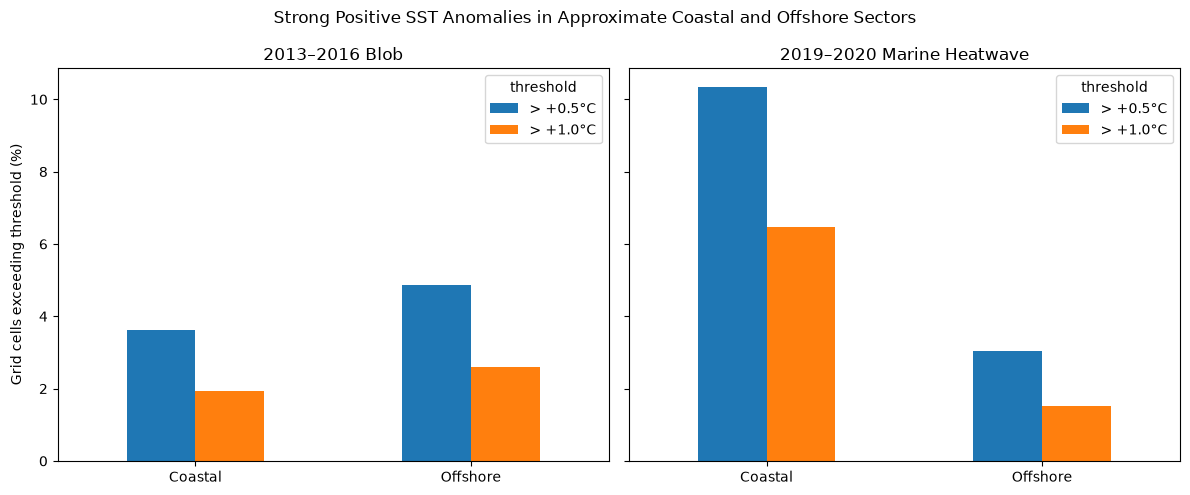

In [ ]:
# plot the figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

# Blob
blob_plot = strong_anomaly_long[
    strong_anomaly_long["event"] == "2013–2016 Blob"
]

blob_pivot = blob_plot.pivot(
    index="zone",
    columns="threshold",
    values="percentage"
)

blob_pivot.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("2013–2016 Blob")
axes[0].set_xlabel("")
axes[0].set_ylabel("Grid cells exceeding threshold (%)")
axes[0].tick_params(axis="x", rotation=0)


# 2019–2020
mhw_plot = strong_anomaly_long[
    strong_anomaly_long["event"] == "2019–2020 MHW"
]

mhw_pivot = mhw_plot.pivot(
    index="zone",
    columns="threshold",
    values="percentage"
)

mhw_pivot.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("2019–2020 Marine Heatwave")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)


fig.suptitle(
    "Strong Positive SST Anomalies in Approximate Coastal and Offshore Sectors"
)

plt.tight_layout()
plt.show()

*This figure did not end up on the Project Proposal nor the Final Report*

In [ ]:
# Table 1 in our Project Proposal
table = zone_comparison[
    [
        "event",
        "zone",
        "positive_pct",
        "above_05_pct",
        "above_10_pct"
    ]
].copy()

table.columns = [
    "Event",
    "Sector",
    "Positive anomaly (%)",
    "> +0.5°C (%)",
    "> +1.0°C (%)"
]

table = table.round(1)

display(table)

,Event,Sector,Positive anomaly (%),> +0.5°C (%),> +1.0°C (%)
0,2013–2016 Blob,Coastal,57.900002,3.6,1.9
1,2013–2016 Blob,Offshore,63.700001,4.9,2.6
0,2019–2020 MHW,Coastal,39.700001,10.3,6.5
1,2019–2020 MHW,Offshore,38.000000,3.0,1.5


This table is Table 1 of our initial Project Proposal. It compares exploratory SST anomalies between approximate coastal and offshore sectors during the 2 event periods. Percentages represent the proportion of sampled grid cells exceeding each anomaly threshold.

## 6. Explore warm-condition drifter trajectories
Recover trajectory IDs from the GDP structure, select high-quality SST observations, and plot selected drifters experiencing GDP-relative SST anomalies above +1°C. *These exploratory anomalies differ from the OISST-based warm-condition flags in RQ1/RQ2*

In [43]:
traj_ids = np.repeat(
    cc["id"].values,
    cc["rowsize"].values
)

print(len(traj_ids))
print(cc.sizes["obs"])

1412827
1412827


In [44]:
traj_df = pd.DataFrame({
    "time": cc["time"].values,
    "lat": cc["lat"].values,
    "lon": cc["lon"].values,
    "sst": cc["sst"].values,
    "flg_sst": cc["flg_sst"].values,
    "traj_id": traj_ids
})

In [45]:
traj_df["sst_c"] = traj_df["sst"] - 273.15

traj_df = traj_df[
    (traj_df["flg_sst"] == 5) &
    (traj_df["sst"].notna())
].copy()

print(len(traj_df))
traj_df.head()

1358083


,time,lat,lon,sst,flg_sst,traj_id,sst_c
0,2013-06-08 09:00:00,46.073181,-134.991623,284.843994,5,70917,11.694000
1,2013-06-08 10:00:00,46.077641,-134.981186,284.825012,5,70917,11.675018
2,2013-06-08 11:00:00,46.069801,-134.971878,284.792999,5,70917,11.643005
3,2013-06-08 12:00:00,46.065510,-134.960922,284.760986,5,70917,11.610992
4,2013-06-08 13:00:00,46.059978,-134.951523,284.743011,5,70917,11.593018


In [46]:
traj_df["year"] = traj_df["time"].dt.year
traj_df["month"] = traj_df["time"].dt.month

grid_size = 0.5

traj_df["lat_bin"] = (
    np.floor(traj_df["lat"] / grid_size)
    * grid_size
)

traj_df["lon_bin"] = (
    np.floor(traj_df["lon"] / grid_size)
    * grid_size
)

In [47]:
traj_df = traj_df.merge(
    climatology,
    on=["lat_bin", "lon_bin", "month"],
    how="left"
)

In [48]:
traj_df["sst_anomaly"] = (
    traj_df["sst_c"] -
    traj_df["baseline_sst"]
)

In [50]:
blob_traj = traj_df[
    (traj_df["year"] >= 2013) &
    (traj_df["year"] <= 2016)
].copy()

mhw_traj = traj_df[
    (traj_df["year"] >= 2019) &
    (traj_df["year"] <= 2020)
].copy()

There are 543427 Blob observations and 300514 2019-2020 MHW observations. There are 120 Blob drifters and only 84 MHW drifters.

In [52]:
strong_threshold = 1.0

blob_traj["strong_warm"] = (
    blob_traj["sst_anomaly"] > strong_threshold
)

mhw_traj["strong_warm"] = (
    mhw_traj["sst_anomaly"] > strong_threshold
)

print(
    "Blob strong warm observations:",
    blob_traj["strong_warm"].sum()
)

print(
    "2019–2020 strong warm observations:",
    mhw_traj["strong_warm"].sum()
)

Blob strong warm observations: 40267
2019–2020 strong warm observations: 13703


In [53]:
blob_warm_counts = (
    blob_traj
    .groupby("traj_id")["strong_warm"]
    .sum()
    .sort_values(ascending=False)
)

blob_warm_counts.head(10)

traj_id
101916    2935
139476    1652
114868    1495
139475    1435
115003    1378
114890    1240
139498    1218
116215    1062
118543     994
132553     994
Name: strong_warm, dtype: int64

In [54]:
mhw_warm_counts = (
    mhw_traj
    .groupby("traj_id")["strong_warm"]
    .sum()
    .sort_values(ascending=False)
)

mhw_warm_counts.head(10)

traj_id
300234065704160    753
300234068246260    571
300234066814350    527
300234063892830    505
300234066814360    492
300234068247830    486
300234066021040    428
300234066612850    417
300234068246970    417
300234066815220    416
Name: strong_warm, dtype: int64

In [55]:
blob_warm_counts = blob_warm_counts[
    blob_warm_counts > 0
]

mhw_warm_counts = mhw_warm_counts[
    mhw_warm_counts > 0
]

In [56]:
print(
    "Blob drifters experiencing > +1°C:",
    len(blob_warm_counts)
)

print(
    "2019–2020 drifters experiencing > +1°C:",
    len(mhw_warm_counts)
)

Blob drifters experiencing > +1°C: 102
2019–2020 drifters experiencing > +1°C: 71


In [57]:
n_drifters = 8

blob_top_ids = (
    blob_warm_counts
    .head(n_drifters)
    .index
)

mhw_top_ids = (
    mhw_warm_counts
    .head(n_drifters)
    .index
)

In [58]:
blob_top = blob_traj[
    blob_traj["traj_id"].isin(blob_top_ids)
].copy()

mhw_top = mhw_traj[
    mhw_traj["traj_id"].isin(mhw_top_ids)
].copy()

In [59]:
blob_top = blob_top.sort_values(
    ["traj_id", "time"]
)

mhw_top = mhw_top.sort_values(
    ["traj_id", "time"]
)

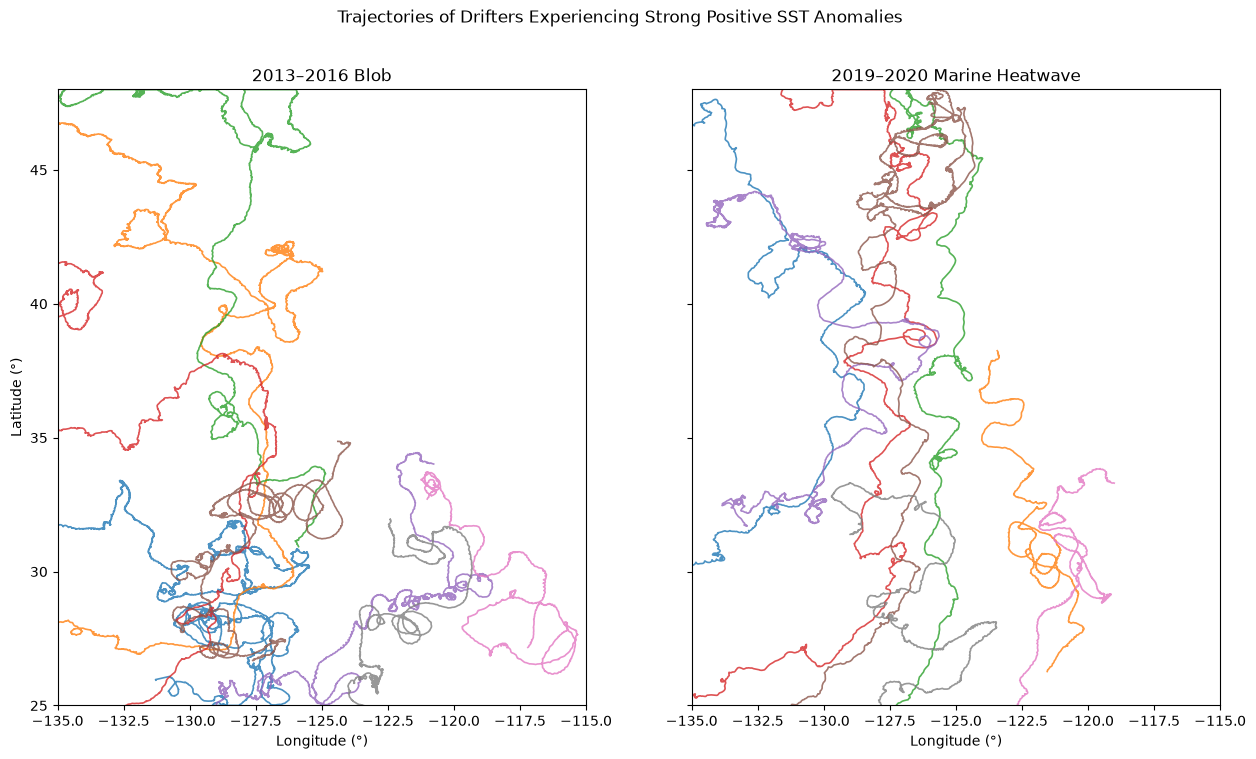

In [ ]:
# plot the figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    sharex=True,
    sharey=True
)

for traj_id, group in blob_top.groupby("traj_id"):
    axes[0].plot(
        group["lon"],
        group["lat"],
        linewidth=1.2,
        alpha=0.8
    )

axes[0].set_title("2013–2016 Blob")
axes[0].set_xlabel("Longitude (°)")
axes[0].set_ylabel("Latitude (°)")
axes[0].set_xlim(-135, -115)
axes[0].set_ylim(25, 48)


for traj_id, group in mhw_top.groupby("traj_id"):
    axes[1].plot(
        group["lon"],
        group["lat"],
        linewidth=1.2,
        alpha=0.8
    )

axes[1].set_title("2019–2020 Marine Heatwave")
axes[1].set_xlabel("Longitude (°)")
axes[1].set_xlim(-135, -115)
axes[1].set_ylim(25, 48)

fig.suptitle(
    "Trajectories of Drifters Experiencing Strong Positive SST Anomalies"
)

plt.show()

*This figure did not end up on the project proposal nor the final report*

In [61]:
from matplotlib.colors import TwoSlopeNorm

In [62]:
all_top_anomalies = pd.concat([
    blob_top["sst_anomaly"],
    mhw_top["sst_anomaly"]
]).dropna()

anomaly_limit = max(
    abs(all_top_anomalies.quantile(0.02)),
    abs(all_top_anomalies.quantile(0.98))
)

norm = TwoSlopeNorm(
    vmin=-anomaly_limit,
    vcenter=0,
    vmax=anomaly_limit
)

print(anomaly_limit)

2.430676269531247


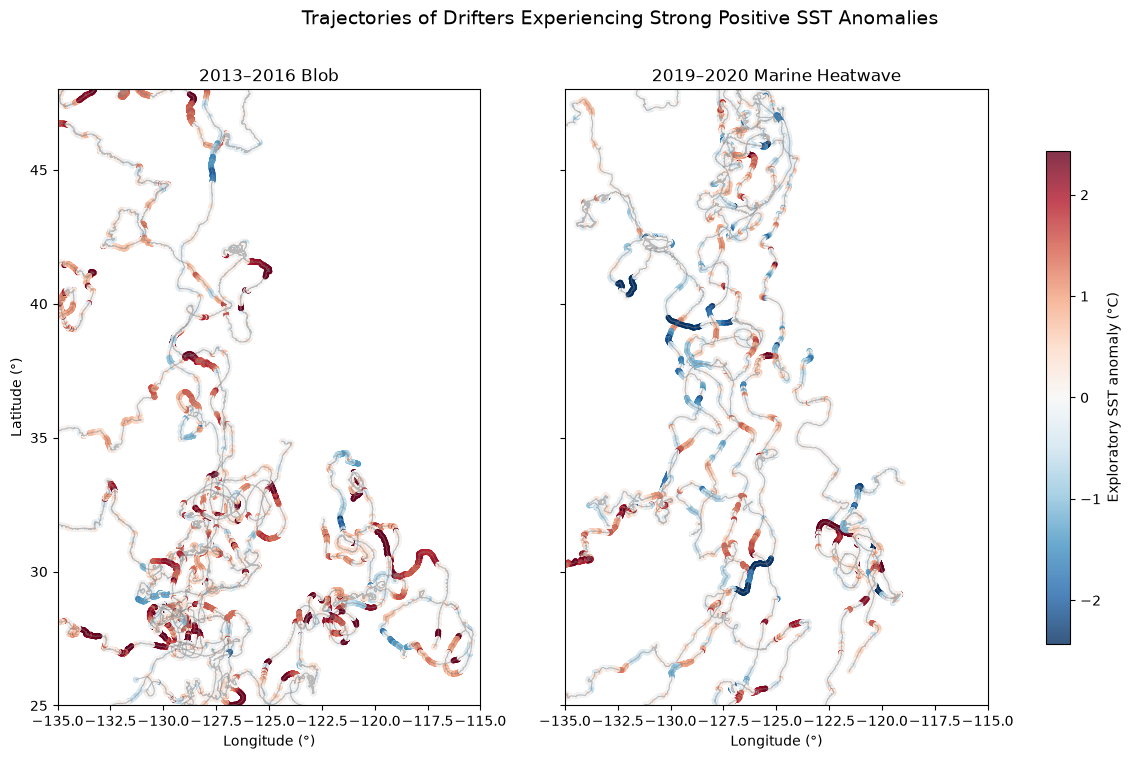

In [63]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    sharex=True,
    sharey=True
)


# ------------------
# Blob
# ------------------

for traj_id, group in blob_top.groupby("traj_id"):

    axes[0].plot(
        group["lon"],
        group["lat"],
        color="grey",
        linewidth=0.8,
        alpha=0.5
    )

sc1 = axes[0].scatter(
    blob_top["lon"],
    blob_top["lat"],
    c=blob_top["sst_anomaly"],
    cmap="RdBu_r",
    norm=norm,
    s=8,
    alpha=0.8
)

axes[0].set_title("2013–2016 Blob")
axes[0].set_xlabel("Longitude (°)")
axes[0].set_ylabel("Latitude (°)")
axes[0].set_xlim(-135, -115)
axes[0].set_ylim(25, 48)


# ------------------
# 2019–2020
# ------------------

for traj_id, group in mhw_top.groupby("traj_id"):

    axes[1].plot(
        group["lon"],
        group["lat"],
        color="grey",
        linewidth=0.8,
        alpha=0.5
    )

sc2 = axes[1].scatter(
    mhw_top["lon"],
    mhw_top["lat"],
    c=mhw_top["sst_anomaly"],
    cmap="RdBu_r",
    norm=norm,
    s=8,
    alpha=0.8
)

axes[1].set_title("2019–2020 Marine Heatwave")
axes[1].set_xlabel("Longitude (°)")
axes[1].set_xlim(-135, -115)
axes[1].set_ylim(25, 48)


# Colourbar
cbar = fig.colorbar(
    sc2,
    ax=axes,
    shrink=0.8
)

cbar.set_label(
    "Exploratory SST anomaly (°C)"
)

fig.suptitle(
    "Trajectories of Drifters Experiencing Strong Positive SST Anomalies",
    fontsize=14
)

plt.show()

*This is Figure 2 in our Project Proposal, but it is not in our Final Report*

## 7. Exploratory offshore-to-coastal-sector transitions
For drifters with an offshore SST anomaly above +1°C, check whether a subsequent observation falls in the longitude-defined coastal sector.

In [ ]:
def offshore_to_coastal_summary(df):

    results = []

    for traj_id, group in df.groupby("traj_id"):

        group = group.sort_values("time")

        # strong warm observations while offshore
        warm_offshore = group[
            (group["lon"] < -125) &
            (group["sst_anomaly"] > 1.0)
        ]

        # skip drifters that never experienced
        # a strong anomaly offshore
        if len(warm_offshore) == 0:
            continue

        # first time strong offshore warmth was observed
        first_warm_time = warm_offshore["time"].min()

        # everything occurring afterwards
        later = group[
            group["time"] > first_warm_time
        ]

        # did the drifter subsequently enter coastal sector?
        entered_coastal = (
            later["lon"] >= -125
        ).any()

        results.append({
            "traj_id": traj_id,
            "first_warm_offshore_time": first_warm_time,
            "entered_coastal_after": entered_coastal
        })

    return pd.DataFrame(results)

In [65]:
blob_transport = offshore_to_coastal_summary(
    blob_traj
)

mhw_transport = offshore_to_coastal_summary(
    mhw_traj
)

display(blob_transport.head())
display(mhw_transport.head())

,traj_id,first_warm_offshore_time,entered_coastal_after
0,39994,2013-03-31 21:00:00,False
1,39995,2013-03-13 20:00:00,False
2,39997,2013-01-01 14:00:00,False
3,70917,2013-06-30 22:00:00,False
4,101674,2013-08-21 23:00:00,False


,traj_id,first_warm_offshore_time,entered_coastal_after
0,300234063242490,2019-01-05 04:00:00,True
1,300234063243480,2019-01-04 19:00:00,False
2,300234063320730,2019-01-05 16:00:00,True
3,300234063472530,2019-04-18 22:00:00,False
4,300234063891650,2020-03-15 01:00:00,False


In [66]:
blob_total = len(blob_transport)

blob_entered = (
    blob_transport["entered_coastal_after"].sum()
)

blob_pct = (
    blob_entered / blob_total * 100
)


mhw_total = len(mhw_transport)

mhw_entered = (
    mhw_transport["entered_coastal_after"].sum()
)

mhw_pct = (
    mhw_entered / mhw_total * 100
)

In [67]:
transport_comparison = pd.DataFrame({
    "Event": [
        "2013–2016 Blob",
        "2019–2020 MHW"
    ],

    "Drifters with >+1°C offshore anomaly": [
        blob_total,
        mhw_total
    ],

    "Later entered coastal sector": [
        blob_entered,
        mhw_entered
    ],

    "Later entered coastal sector (%)": [
        blob_pct,
        mhw_pct
    ]
})

transport_comparison.round(1)

,Event,Drifters with >+1°C offshore anomaly,Later entered coastal sector,Later entered coastal sector (%)
0,2013–2016 Blob,66,22,33.3
1,2019–2020 MHW,66,8,12.1


## 8. Plot selected offshore-to-coastal sector pathways
Show pathways from the first strong offshore anomaly to the first subsequent entry into the approximate longitude-defined coastal sector.

In [ ]:
# initial checks
blob_coastal_ids = blob_transport.loc[
    blob_transport["entered_coastal_after"] == True,
    "traj_id"
]

mhw_coastal_ids = mhw_transport.loc[
    mhw_transport["entered_coastal_after"] == True,
    "traj_id"
]

print("Blob qualifying trajectories:", len(blob_coastal_ids))
print("2019–2020 qualifying trajectories:", len(mhw_coastal_ids))

Blob qualifying trajectories: 22
2019–2020 qualifying trajectories: 8


In [ ]:
# function to fetch coastal entry paths for qualifying drifters
def get_coastal_entry_paths(event_df, transport_df):

    paths = []

    qualifying = transport_df[
        transport_df["entered_coastal_after"] == True
    ]

    for _, row in qualifying.iterrows():

        traj_id = row["traj_id"]
        start_time = row["first_warm_offshore_time"]

        group = event_df[
            (event_df["traj_id"] == traj_id) &
            (event_df["time"] >= start_time)
        ].copy()

        group = group.sort_values("time")

        # Find first subsequent observation in coastal sector
        coastal_obs = group[
            (group["lon"] >= -125) &
            (group["time"] > start_time)
        ]

        if len(coastal_obs) == 0:
            continue

        coastal_time = coastal_obs["time"].iloc[0]

        # Keep only pathway from warm offshore observation
        # until first coastal entry
        path = group[
            group["time"] <= coastal_time
        ].copy()

        path["coastal_entry_time"] = coastal_time

        paths.append(path)

    return pd.concat(paths, ignore_index=True)

In [ ]:
# retrieve coastal entry paths for qualifying drifters
blob_paths = get_coastal_entry_paths(
    blob_traj,
    blob_transport
)

mhw_paths = get_coastal_entry_paths(
    mhw_traj,
    mhw_transport
)

print(
    "Blob trajectories:",
    blob_paths["traj_id"].nunique()
)

print(
    "2019–2020 trajectories:",
    mhw_paths["traj_id"].nunique()
)

Blob trajectories: 22
2019–2020 trajectories: 8


In [71]:
blob_start = (
    blob_paths
    .sort_values("time")
    .groupby("traj_id")
    .first()
    .reset_index()
)

blob_end = (
    blob_paths
    .sort_values("time")
    .groupby("traj_id")
    .last()
    .reset_index()
)

mhw_start = (
    mhw_paths
    .sort_values("time")
    .groupby("traj_id")
    .first()
    .reset_index()
)

mhw_end = (
    mhw_paths
    .sort_values("time")
    .groupby("traj_id")
    .last()
    .reset_index()
)

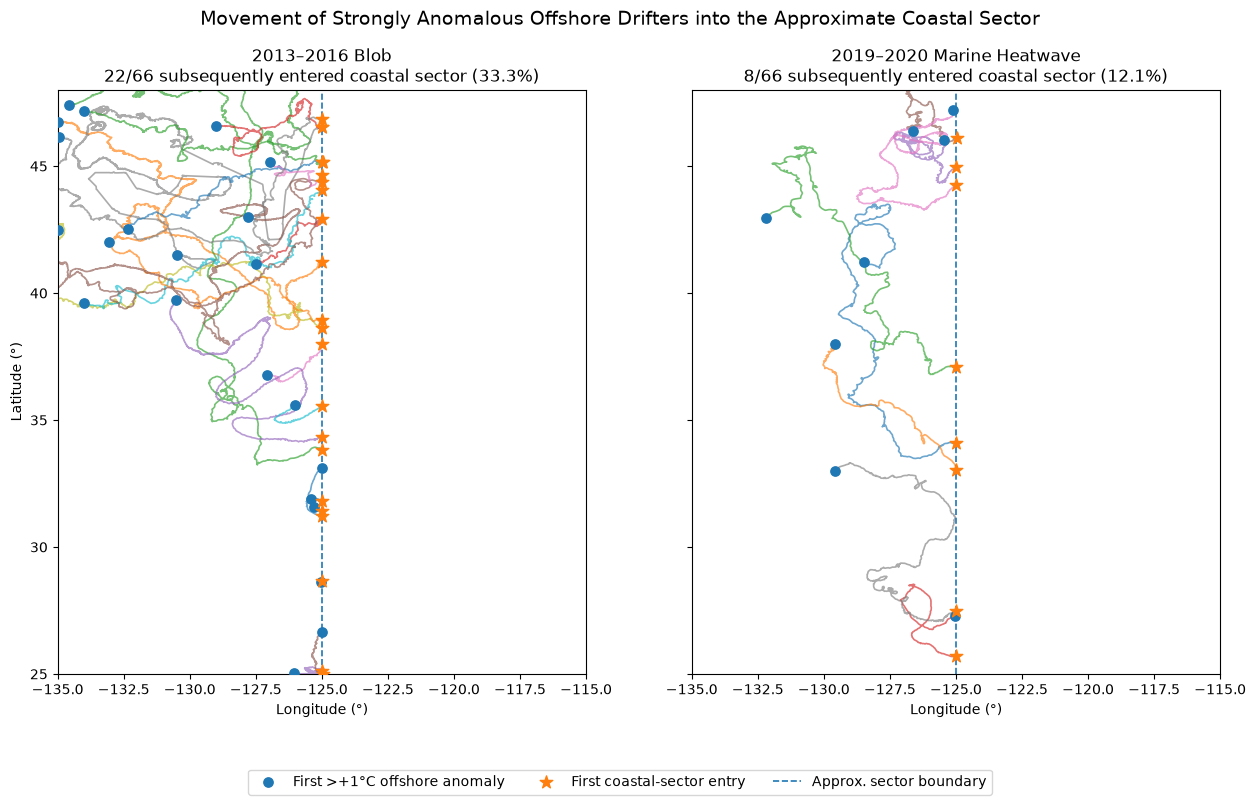

In [ ]:
# plot the figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    sharex=True,
    sharey=True
)


# -----------------------------
# 2013–2016 Blob
# -----------------------------

for traj_id, group in blob_paths.groupby("traj_id"):

    group = group.sort_values("time")

    axes[0].plot(
        group["lon"],
        group["lat"],
        linewidth=1.2,
        alpha=0.65
    )

axes[0].scatter(
    blob_start["lon"],
    blob_start["lat"],
    marker="o",
    s=45,
    label="First >+1°C offshore anomaly",
    zorder=3
)

axes[0].scatter(
    blob_end["lon"],
    blob_end["lat"],
    marker="*",
    s=90,
    label="First coastal-sector entry",
    zorder=4
)

axes[0].axvline(
    -125,
    linestyle="--",
    linewidth=1.2,
    label="Approx. sector boundary"
)

axes[0].set_title(
    "2013–2016 Blob\n22/66 subsequently entered coastal sector (33.3%)"
)

axes[0].set_xlabel("Longitude (°)")
axes[0].set_ylabel("Latitude (°)")
axes[0].set_xlim(-135, -115)
axes[0].set_ylim(25, 48)


# -----------------------------
# 2019–2020 MHW
# -----------------------------

for traj_id, group in mhw_paths.groupby("traj_id"):

    group = group.sort_values("time")

    axes[1].plot(
        group["lon"],
        group["lat"],
        linewidth=1.2,
        alpha=0.65
    )

axes[1].scatter(
    mhw_start["lon"],
    mhw_start["lat"],
    marker="o",
    s=45,
    label="First >+1°C offshore anomaly",
    zorder=3
)

axes[1].scatter(
    mhw_end["lon"],
    mhw_end["lat"],
    marker="*",
    s=90,
    label="First coastal-sector entry",
    zorder=4
)

axes[1].axvline(
    -125,
    linestyle="--",
    linewidth=1.2,
    label="Approx. sector boundary"
)

axes[1].set_title(
    "2019–2020 Marine Heatwave\n8/66 subsequently entered coastal sector (12.1%)"
)

axes[1].set_xlabel("Longitude (°)")
axes[1].set_xlim(-135, -115)
axes[1].set_ylim(25, 48)


fig.suptitle(
    "Movement of Strongly Anomalous Offshore Drifters into the Approximate Coastal Sector",
    fontsize=14
)

# One legend instead of duplicate legends
handles, labels = axes[1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.01)
)

plt.subplots_adjust(
    bottom=0.15,
    top=0.88
)

plt.show()

*Exploratory pathway visualisation. This figure was not included in the final report because the final coastal-exposure analysis uses distance to the mapped coastline rather than a longitude-based coastal sector.*

## 9. Summarise velocities along selected pathways
Calculate speed from eastward and northward GDP velocities, then summarise observation-level and drifter-level values.

In [74]:
velocity_df = pd.DataFrame({
    "time": cc["time"].values,
    "lat": cc["lat"].values,
    "lon": cc["lon"].values,
    "traj_id": traj_ids,
    "ve": cc["ve"].values,
    "vn": cc["vn"].values
})

In [75]:
velocity_df["speed"] = np.sqrt(
    velocity_df["ve"]**2 +
    velocity_df["vn"]**2
)

In [76]:
blob_paths_velocity = blob_paths.merge(
    velocity_df,
    on=["traj_id", "time", "lat", "lon"],
    how="left"
)

mhw_paths_velocity = mhw_paths.merge(
    velocity_df,
    on=["traj_id", "time", "lat", "lon"],
    how="left"
)

In [78]:
velocity_comparison = pd.DataFrame({
    "Metric": [
        "Median speed (m/s)",
        "Median eastward velocity (m/s)",
        "Median northward velocity (m/s)",
        "Eastward-moving observations (%)"
    ],

    "2013–2016 Blob": [
        blob_paths_velocity["speed"].median(),
        blob_paths_velocity["ve"].median(),
        blob_paths_velocity["vn"].median(),
        (blob_paths_velocity["ve"] > 0).mean() * 100
    ],

    "2019–2020 MHW": [
        mhw_paths_velocity["speed"].median(),
        mhw_paths_velocity["ve"].median(),
        mhw_paths_velocity["vn"].median(),
        (mhw_paths_velocity["ve"] > 0).mean() * 100
    ]
})

velocity_comparison.round(3)

,Metric,2013–2016 Blob,2019–2020 MHW
0,Median speed (m/s),0.204,0.220
1,Median eastward velocity (m/s),0.041,0.032
2,Median northward velocity (m/s),-0.018,-0.052
3,Eastward-moving observations (%),60.007,57.819


In [79]:
blob_velocity_by_drifter = (
    blob_paths_velocity
    .groupby("traj_id")
    .agg(
        median_speed=("speed", "median"),
        median_ve=("ve", "median"),
        median_vn=("vn", "median")
    )
    .reset_index()
)

mhw_velocity_by_drifter = (
    mhw_paths_velocity
    .groupby("traj_id")
    .agg(
        median_speed=("speed", "median"),
        median_ve=("ve", "median"),
        median_vn=("vn", "median")
    )
    .reset_index()
)

In [81]:
drifter_velocity_comparison = pd.DataFrame({
    "Metric": [
        "Median drifter speed (m/s)",
        "Median drifter eastward velocity (m/s)",
        "Median drifter northward velocity (m/s)",
        "Drifters with positive median eastward velocity (%)"
    ],

    "2013–2016 Blob": [
        blob_velocity_by_drifter["median_speed"].median(),
        blob_velocity_by_drifter["median_ve"].median(),
        blob_velocity_by_drifter["median_vn"].median(),
        (blob_velocity_by_drifter["median_ve"] > 0).mean() * 100
    ],

    "2019–2020 MHW": [
        mhw_velocity_by_drifter["median_speed"].median(),
        mhw_velocity_by_drifter["median_ve"].median(),
        mhw_velocity_by_drifter["median_vn"].median(),
        (mhw_velocity_by_drifter["median_ve"] > 0).mean() * 100
    ]
})

drifter_velocity_comparison.round(3)

,Metric,2013–2016 Blob,2019–2020 MHW
0,Median drifter speed (m/s),0.219,0.238
1,Median drifter eastward velocity (m/s),0.088,0.030
2,Median drifter northward velocity (m/s),-0.017,-0.053
3,Drifters with positive median eastward velocit...,86.364,100.000


## 10. Summary and Next Steps
This notebook explored the spatial distribution of SST anomalies, drifter trajectories, coastal and offshore patterns, and velocity characteristics during the 2013–2016 Blob and 2019–2020 marine heatwave.

These exploratory analyses helped identify differences in drifter movement and temperature patterns between the two events. The coastal-sector comparisons and monthly SST anomalies are preliminary measures and differ from the final definitions used in RQ1 and RQ2.

The following notebooks use historical OISST climatology for marine heatwave detection and a 50 km coastline-distance threshold for coastal exposure analysis.